# Лабораторная работа №5. Визуализация данных

Источник данных: `weather1.csv`, наблюдения за погодой в Перми за 2021 год.

В работе использованы библиотеки `pandas`, `matplotlib` и `seaborn`. Ниже приведены исходный код и результаты выполнения всех пунктов задания.

## Пункты 1–9

Загружены столбцы местного времени, температуры `T`, давления `P`, влажности `U`, скорости ветра `Ff`, облачности `N`, высоты основания облаков `H` и горизонтальной видимости `VV`. Для каждого пункта построен требуемый график.

Наблюдений: 2919
Период: 01.01.2021 02:00 — 31.12.2021 23:00
Корреляция T и U: -0.437

Среднемесячная температура (°C):
Месяц
Янв   -12.96
Фев   -17.42
Мар    -5.66
Апр     5.38
Май    16.28
Июн    18.90
Июл    18.44
Авг    18.57
Сен     7.56
Окт     4.21
Ноя    -3.63
Дек   -10.39

Наблюдения по облачности:
Облачность
100%.                                                                 1427
Облаков нет.                                                           364
70 – 80%.                                                              285
20–30%.                                                                251
90  или более, но не 100%                                              222
40%.                                                                   111
60%.                                                                   106
50%.                                                                    83
10%  или менее, но не 0                                                 66
Нет д

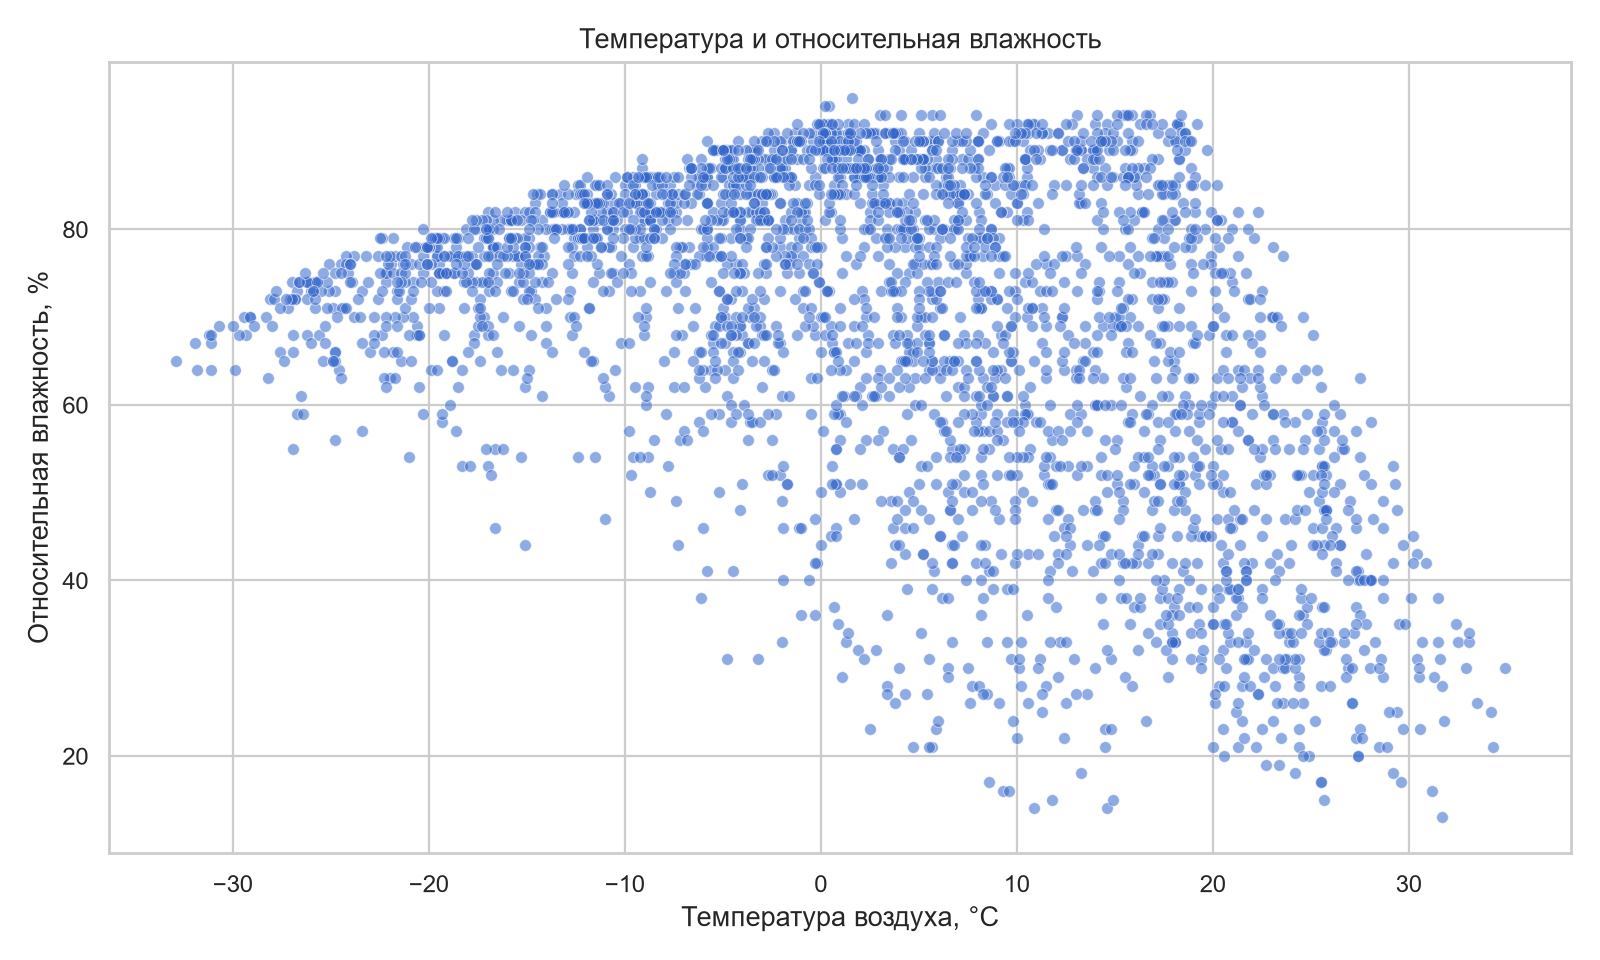

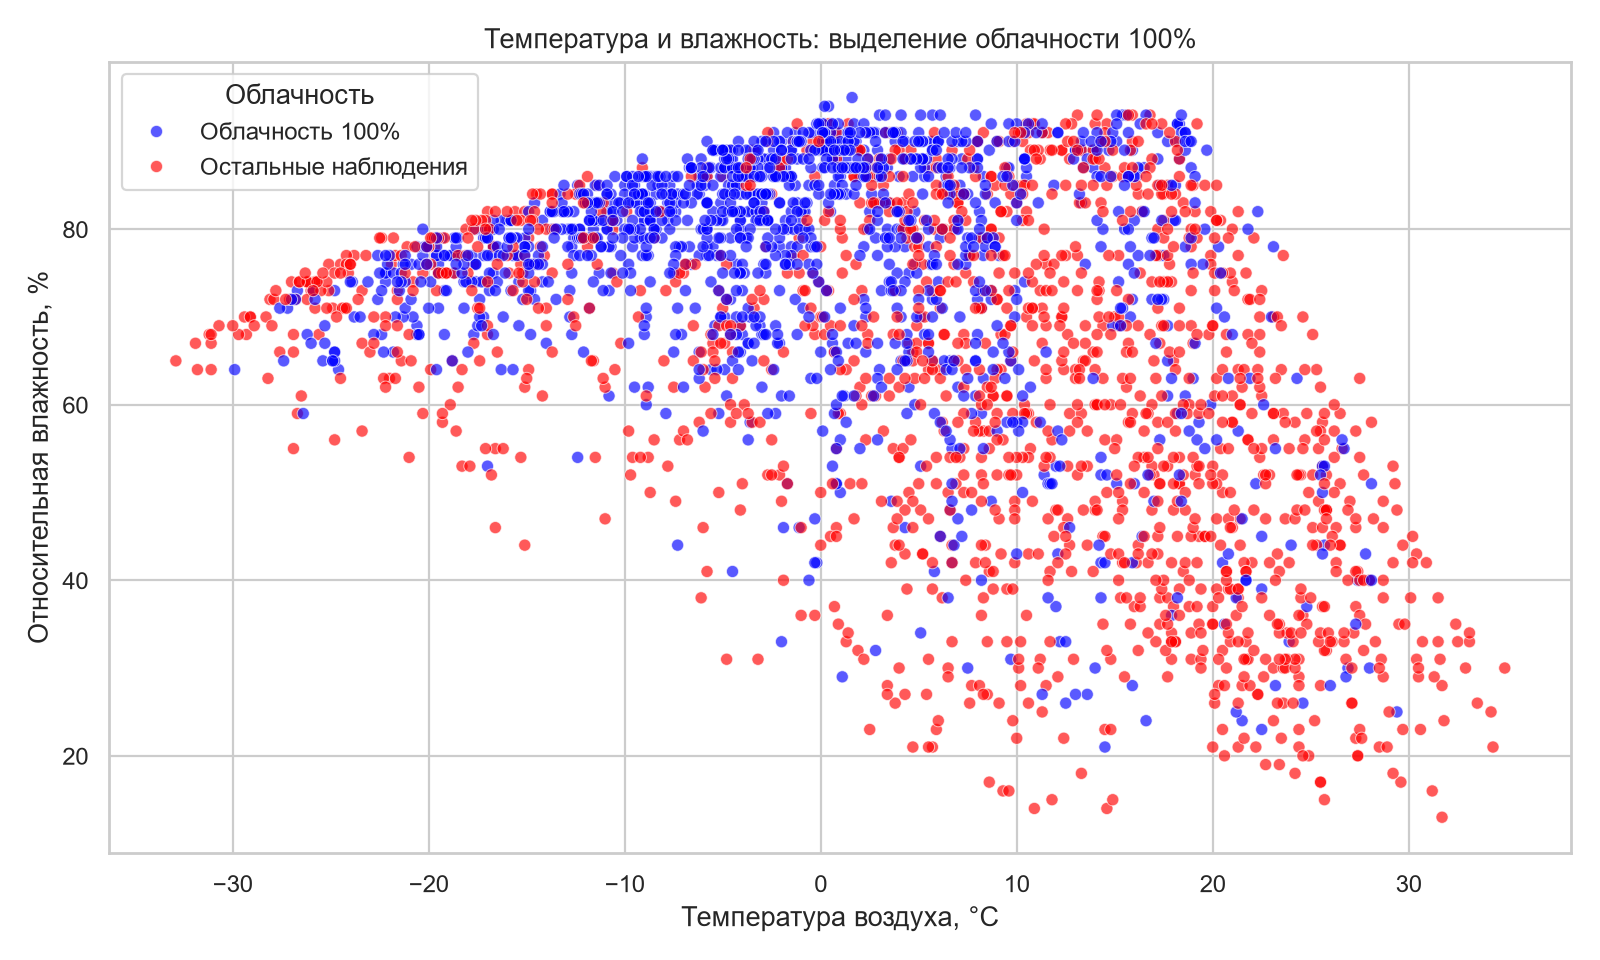

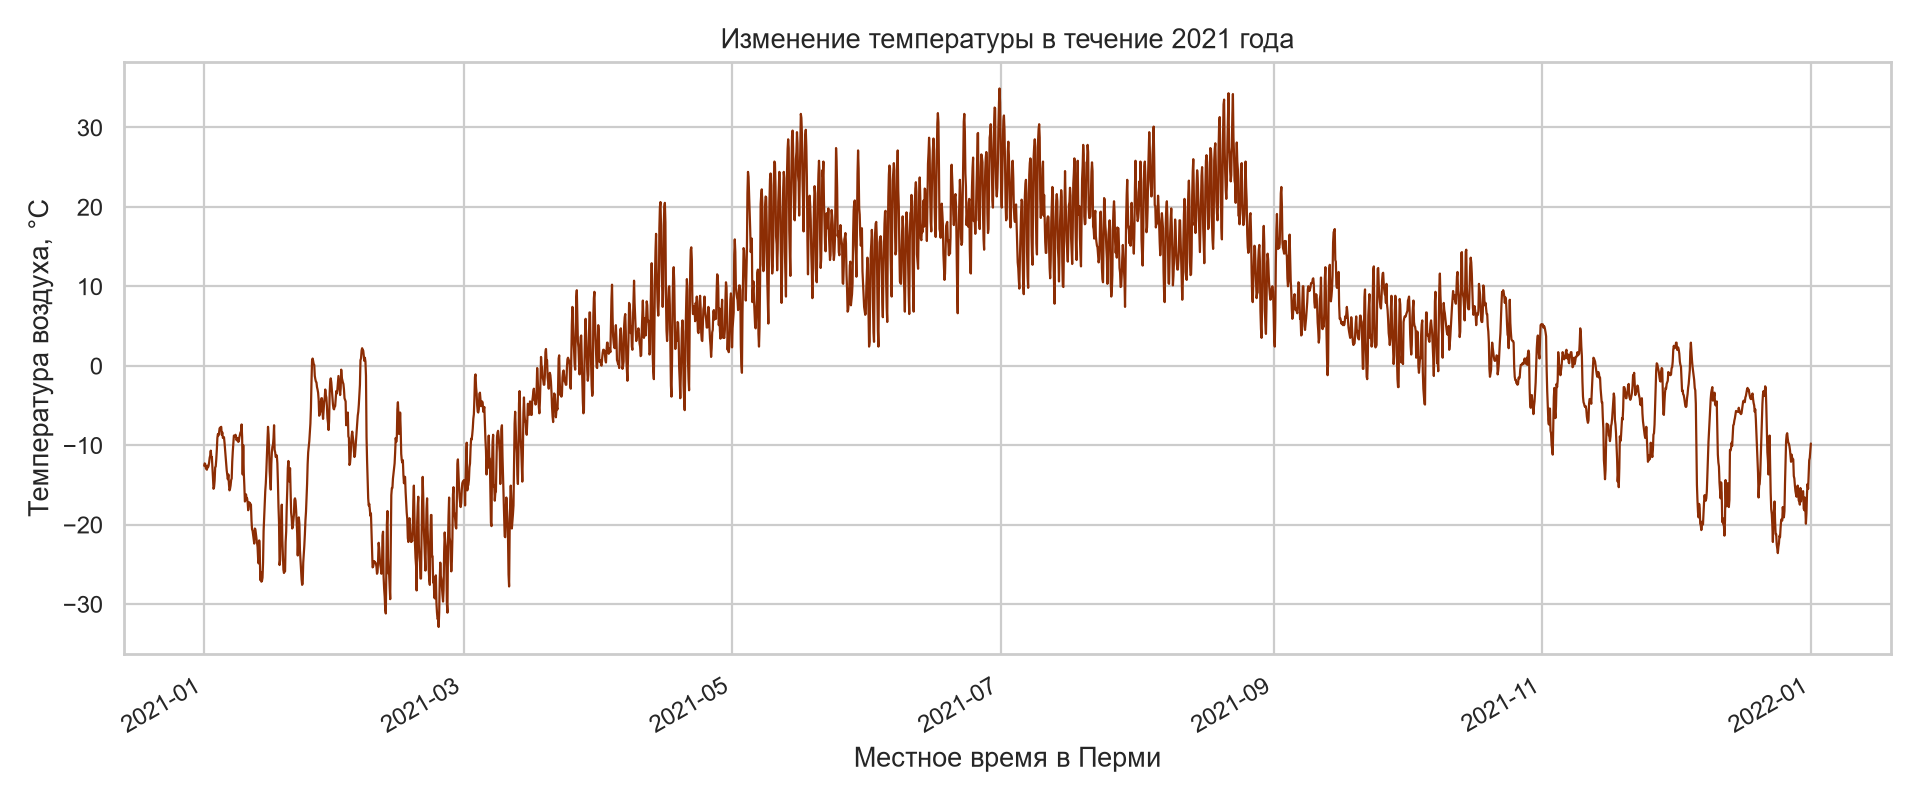

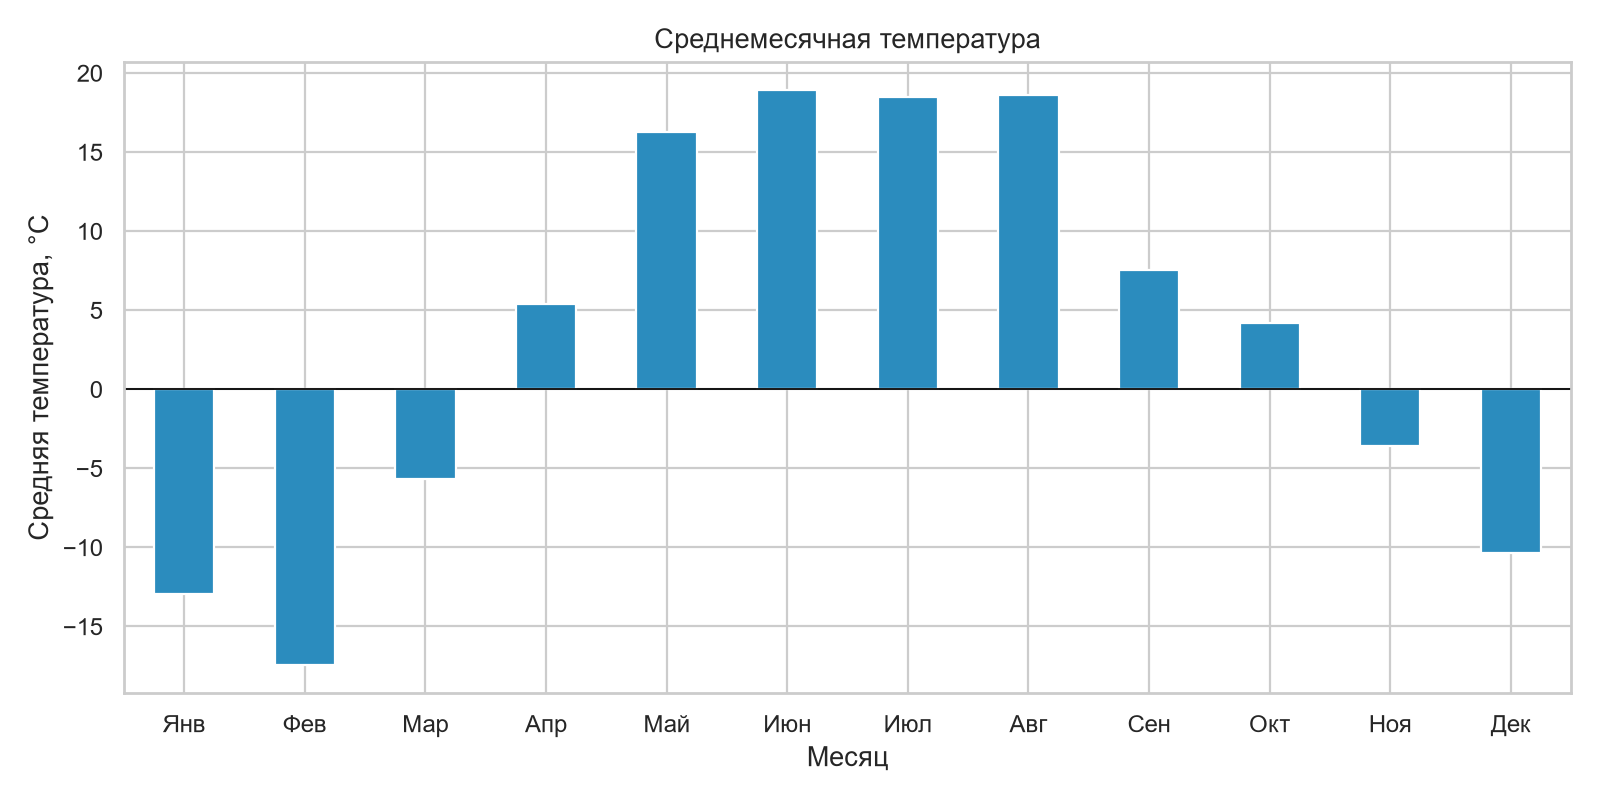

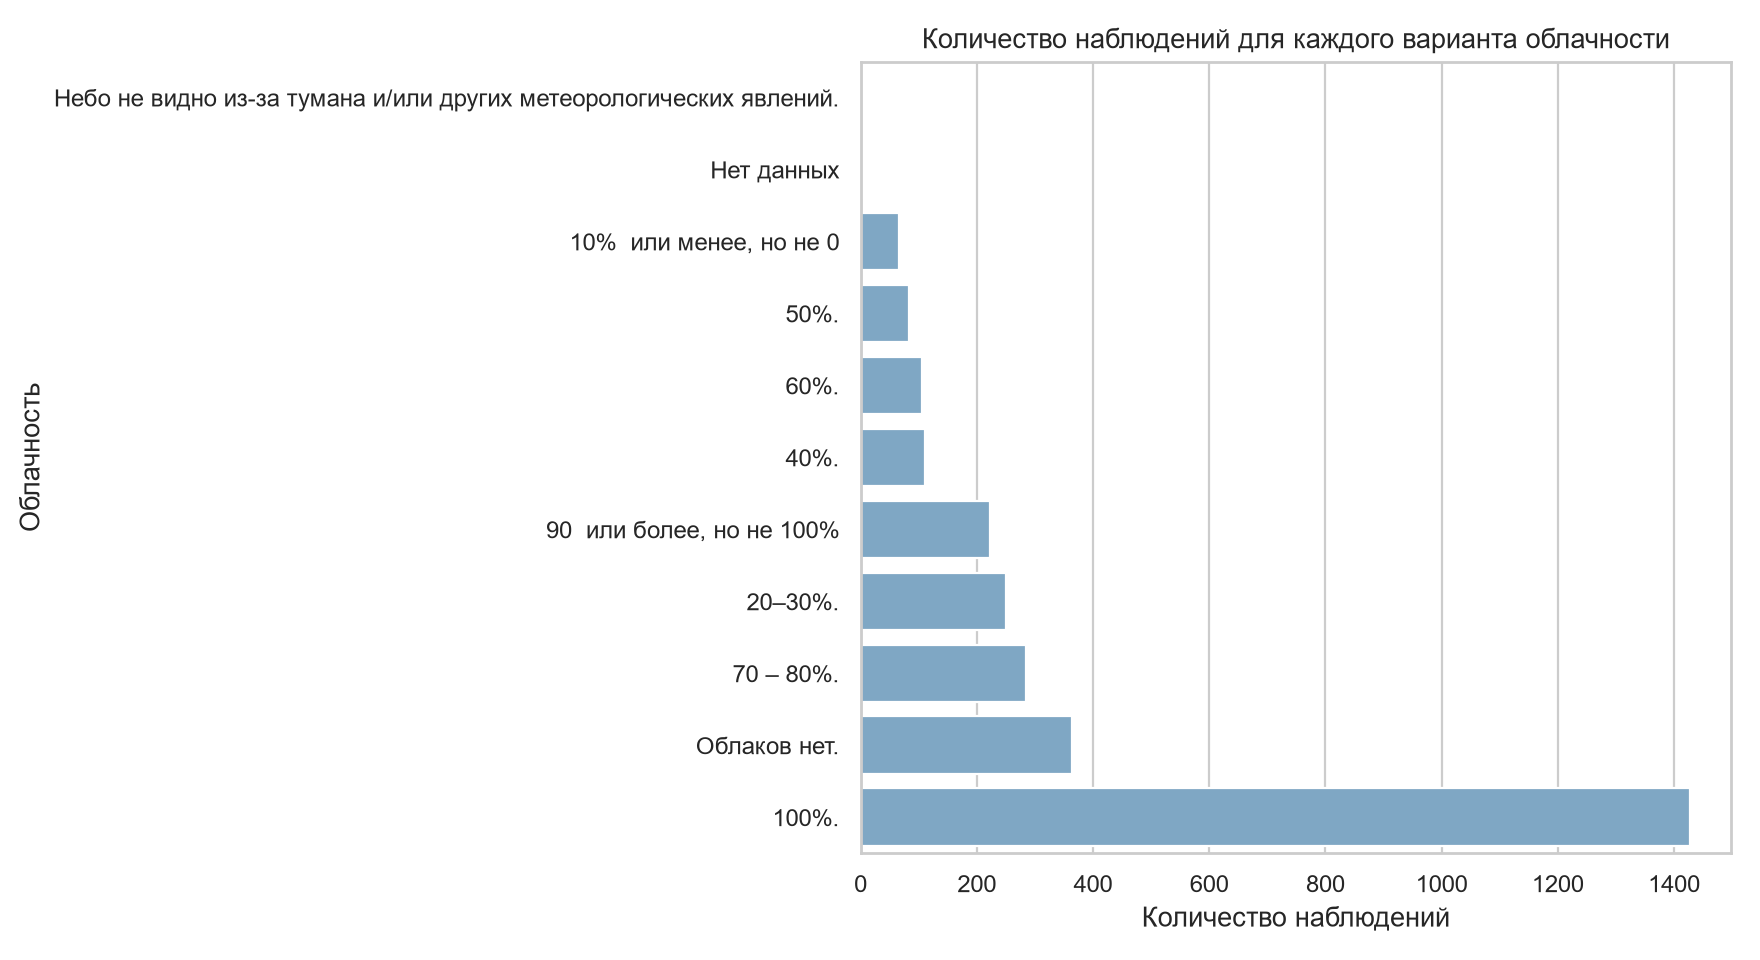

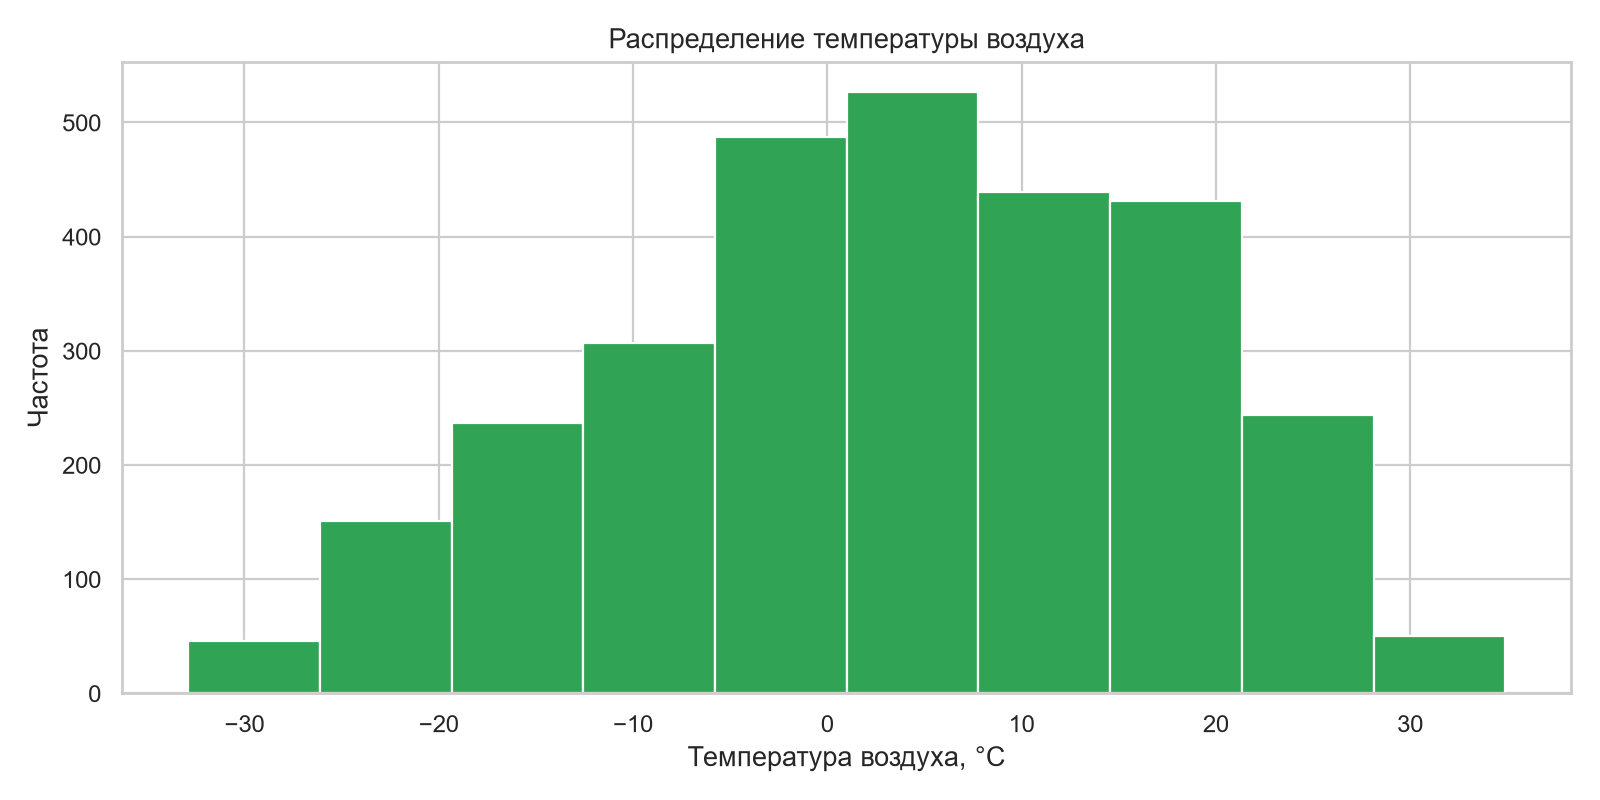

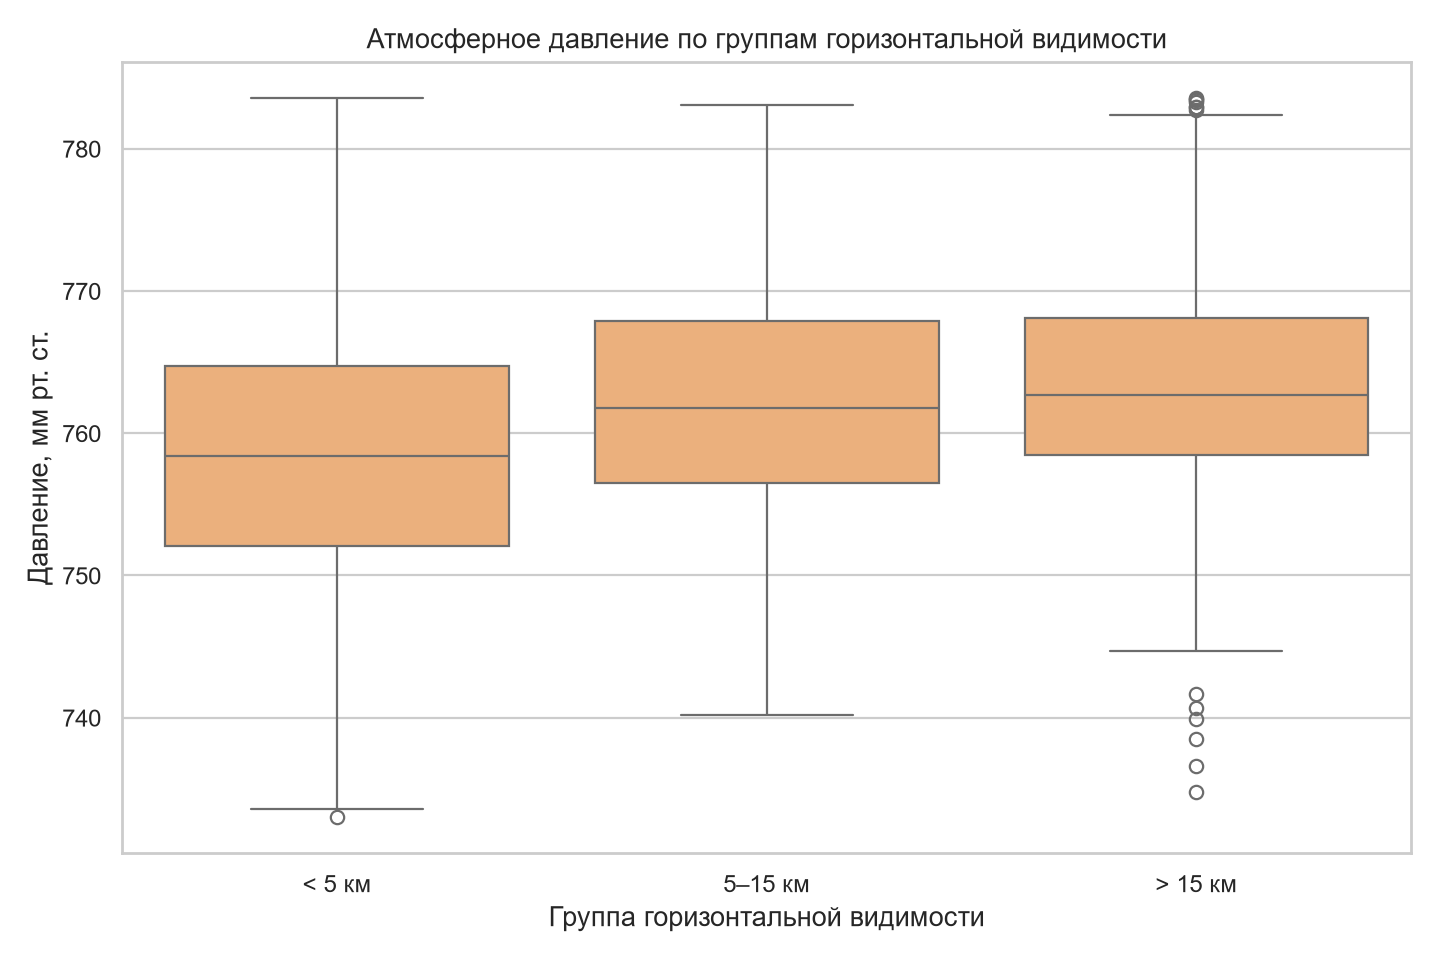

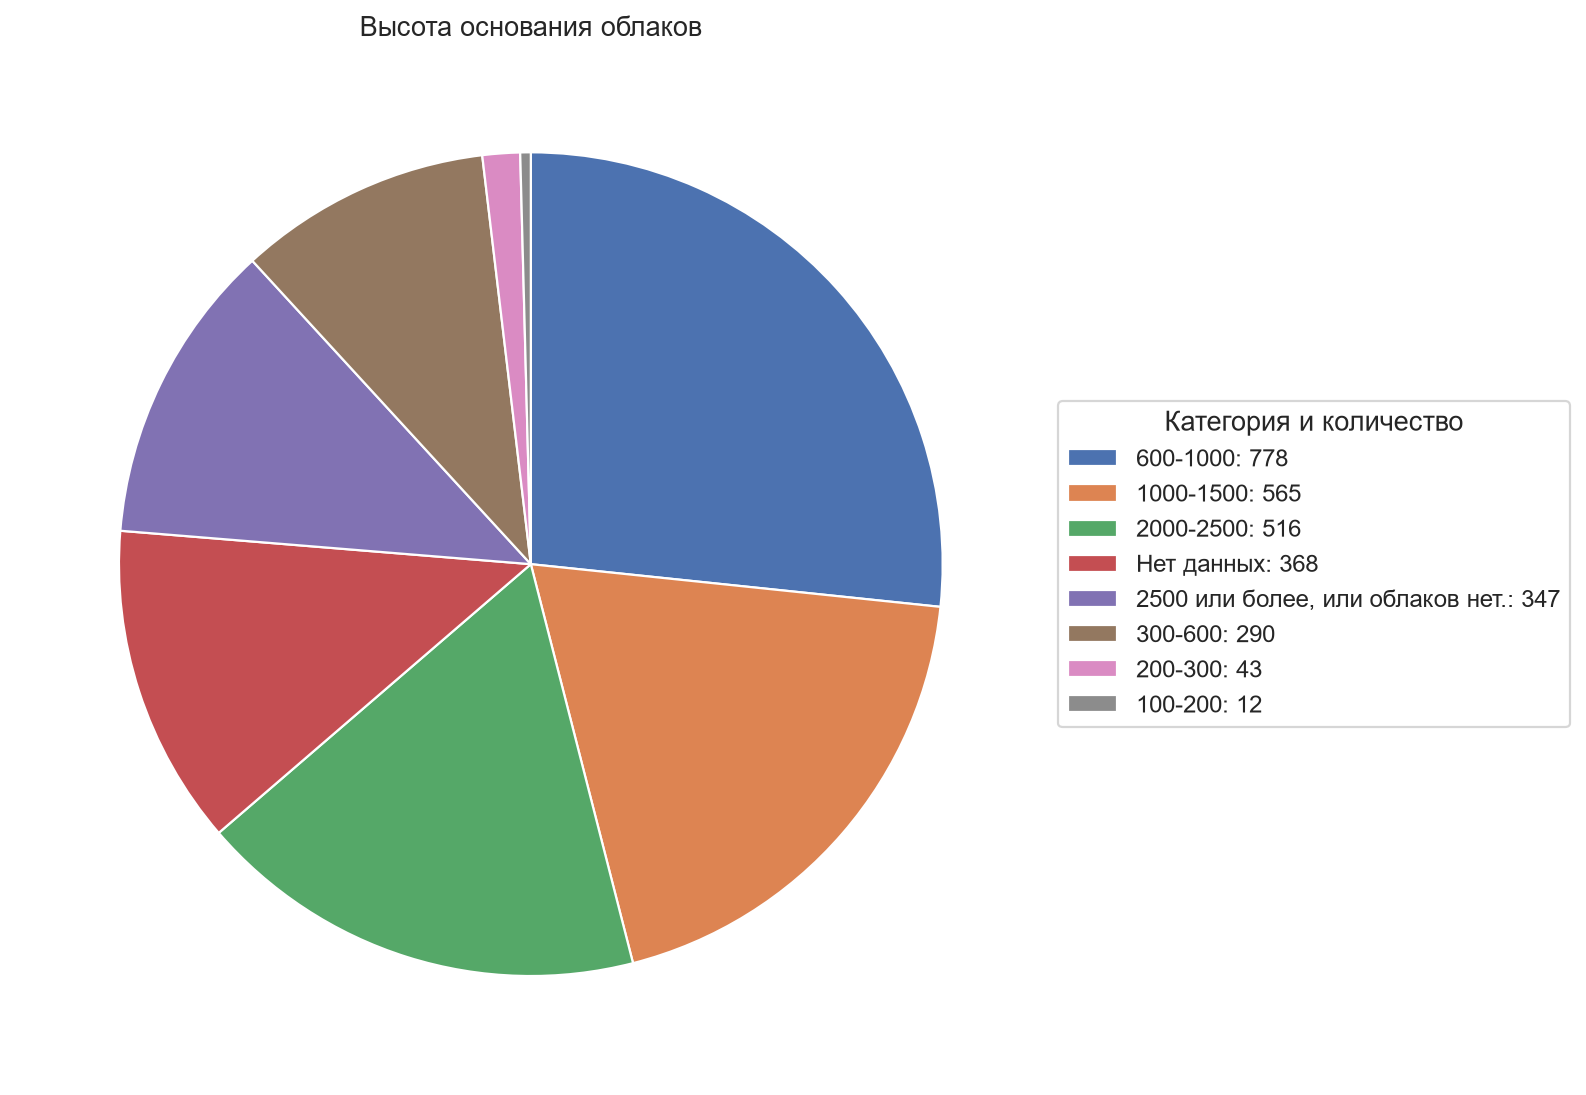

In [1]:
"""Лабораторная работа №5. Визуализация данных о погоде в Перми.

Скрипт читает weather1.csv, выполняет задания 1–9 и сохраняет графики
в каталог lab05_figures. Для визуализации используются matplotlib и seaborn.
"""

from __future__ import annotations

import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
LOCAL_DEPS = ROOT / "_lab_deps"
if LOCAL_DEPS.exists():
    sys.path.insert(0, str(LOCAL_DEPS))

import seaborn as sns


TIME_COL = "Местное время в Перми"
SELECTED_COLUMNS = [TIME_COL, "T", "P", "U", "Ff", "N", "H", "VV"]
MONTH_NAMES = {
    1: "Янв", 2: "Фев", 3: "Мар", 4: "Апр", 5: "Май", 6: "Июн",
    7: "Июл", 8: "Авг", 9: "Сен", 10: "Окт", 11: "Ноя", 12: "Дек",
}
VISIBILITY_ORDER = ["< 5 км", "5–15 км", "> 15 км"]


def load_data(data_path: Path | None = None) -> pd.DataFrame:
    """Загрузка нужных столбцов и подготовка типов данных."""
    path = data_path or ROOT / "weather1.csv"
    weather = pd.read_csv(
        path,
        sep=";",
        encoding="utf-8-sig",
        usecols=SELECTED_COLUMNS,
    )
    weather[TIME_COL] = pd.to_datetime(
        weather[TIME_COL], format="%d.%m.%Y %H:%M"
    )
    for column in ["T", "P", "U", "Ff", "VV"]:
        weather[column] = pd.to_numeric(weather[column], errors="coerce")

    weather = weather.sort_values(TIME_COL).reset_index(drop=True)
    weather["Месяц"] = weather[TIME_COL].dt.month
    weather["Облачность"] = weather["N"].fillna("Нет данных").astype(str).str.strip()
    weather["Облачность 100%"] = weather["N"].fillna("").astype(str).str.strip().eq("100%.")

    def visibility_group(value: float) -> str:
        if pd.isna(value):
            return "Нет данных"
        if value < 5:
            return "< 5 км"
        if value <= 15:
            return "5–15 км"
        return "> 15 км"

    weather["Группа видимости"] = weather["VV"].map(visibility_group)
    weather["Высота основания облаков"] = (
        weather["H"].fillna("Нет данных").astype(str).str.strip()
    )
    return weather


def run_analysis(data_path: Path | None = None, output_dir: Path | None = None):
    """Выполнение всех пунктов лабораторной и сохранение графиков."""
    weather = load_data(data_path)
    figures = output_dir or ROOT / "lab05_figures"
    figures.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")

    # Пункт 2. Точечная диаграмма T–U.
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.scatterplot(data=weather, x="T", y="U", s=28, alpha=0.55, color="#3366cc", ax=ax)
    ax.set_title("Температура и относительная влажность")
    ax.set_xlabel("Температура воздуха, °C")
    ax.set_ylabel("Относительная влажность, %")
    fig.tight_layout()
    fig.savefig(figures / "02_scatter_temperature_humidity.png", dpi=160)
    plt.close(fig)

    # Пункт 3. Та же диаграмма с выделением 100% облачности.
    fig, ax = plt.subplots(figsize=(10, 6))
    plot_data = weather.copy()
    plot_data["Группа облачности"] = np.where(
        plot_data["Облачность 100%"], "Облачность 100%", "Остальные наблюдения"
    )
    sns.scatterplot(
        data=plot_data,
        x="T",
        y="U",
        hue="Группа облачности",
        hue_order=["Облачность 100%", "Остальные наблюдения"],
        palette={"Облачность 100%": "blue", "Остальные наблюдения": "red"},
        s=30,
        alpha=0.65,
        ax=ax,
    )
    ax.set_title("Температура и влажность: выделение облачности 100%")
    ax.set_xlabel("Температура воздуха, °C")
    ax.set_ylabel("Относительная влажность, %")
    ax.legend(title="Облачность")
    fig.tight_layout()
    fig.savefig(figures / "03_scatter_temperature_humidity_cloudiness.png", dpi=160)
    plt.close(fig)

    # Пункт 4. Изменение температуры во времени.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(weather[TIME_COL], weather["T"], color="#8c2d04", linewidth=1)
    ax.set_title("Изменение температуры в течение 2021 года")
    ax.set_xlabel("Местное время в Перми")
    ax.set_ylabel("Температура воздуха, °C")
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(figures / "04_temperature_over_time.png", dpi=160)
    plt.close(fig)

    # Пункт 5. Среднемесячная температура.
    monthly_mean = weather.groupby("Месяц", sort=True)["T"].mean()
    fig, ax = plt.subplots(figsize=(10, 5))
    monthly_mean.plot(kind="bar", ax=ax, color="#2b8cbe")
    ax.set_title("Среднемесячная температура")
    ax.set_xlabel("Месяц")
    ax.set_ylabel("Средняя температура, °C")
    ax.set_xticklabels([MONTH_NAMES[m] for m in monthly_mean.index], rotation=0)
    ax.axhline(0, color="black", linewidth=0.8)
    fig.tight_layout()
    fig.savefig(figures / "05_monthly_mean_temperature.png", dpi=160)
    plt.close(fig)

    # Пункт 6. Количество наблюдений по вариантам облачности.
    cloud_counts = weather["Облачность"].value_counts().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.barplot(x=cloud_counts.values, y=cloud_counts.index, color="#74a9cf", ax=ax)
    ax.set_title("Количество наблюдений для каждого варианта облачности")
    ax.set_xlabel("Количество наблюдений")
    ax.set_ylabel("Облачность")
    fig.tight_layout()
    fig.savefig(figures / "06_cloudiness_counts.png", dpi=160)
    plt.close(fig)

    # Пункт 7. Гистограмма температуры с 10 интервалами.
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(weather["T"].dropna(), bins=10, color="#31a354", edgecolor="white")
    ax.set_title("Распределение температуры воздуха")
    ax.set_xlabel("Температура воздуха, °C")
    ax.set_ylabel("Частота")
    fig.tight_layout()
    fig.savefig(figures / "07_temperature_histogram_10_bins.png", dpi=160)
    plt.close(fig)

    # Пункт 8. Boxplot давления по группам горизонтальной видимости.
    box_data = weather[weather["Группа видимости"].isin(VISIBILITY_ORDER)].copy()
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.boxplot(
        data=box_data,
        x="Группа видимости",
        y="P",
        order=VISIBILITY_ORDER,
        color="#fdae6b",
        ax=ax,
    )
    ax.set_title("Атмосферное давление по группам горизонтальной видимости")
    ax.set_xlabel("Группа горизонтальной видимости")
    ax.set_ylabel("Давление, мм рт. ст.")
    fig.tight_layout()
    fig.savefig(figures / "08_pressure_boxplot_by_visibility.png", dpi=160)
    plt.close(fig)

    # Пункт 9. Круговая диаграмма высоты основания облаков.
    height_counts = weather["Высота основания облаков"].value_counts()
    fig, ax = plt.subplots(figsize=(10, 7))
    wedges, _ = ax.pie(height_counts.values, startangle=90, counterclock=False)
    ax.set_title("Высота основания облаков")
    ax.legend(
        wedges,
        [f"{label}: {count}" for label, count in height_counts.items()],
        title="Категория и количество",
        loc="center left",
        bbox_to_anchor=(1, 0.5),
    )
    fig.tight_layout()
    fig.savefig(figures / "09_cloud_base_height_pie.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

    monthly_table = monthly_mean.rename(index=MONTH_NAMES).round(2)
    missing = weather[SELECTED_COLUMNS].isna().sum()
    summary = (
        f"Наблюдений: {len(weather)}\n"
        f"Период: {weather[TIME_COL].min():%d.%m.%Y %H:%M} — "
        f"{weather[TIME_COL].max():%d.%m.%Y %H:%M}\n"
        f"Корреляция T и U: {weather[['T', 'U']].corr().loc['T', 'U']:.3f}\n\n"
        f"Среднемесячная температура (°C):\n{monthly_table.to_string()}\n\n"
        f"Наблюдения по облачности:\n{weather['Облачность'].value_counts().to_string()}\n\n"
        f"Наблюдения по группам видимости:\n{weather['Группа видимости'].value_counts().to_string()}\n\n"
        f"Пропуски в выбранных столбцах:\n{missing.to_string()}"
    )
    return weather, summary, sorted(figures.glob("*.png"))


_, result_summary, result_figures = run_analysis()
print(result_summary)
